# SoftAdapt diagnostics on a simple PDE

This standalone experiment solves the 1-D Poisson boundary-value problem

\[
u''(x) = -\pi^2\sin(\pi x),\quad x\in[0,1],\qquad u(0)=u(1)=0,
\]

whose exact solution is $u(x)=\sin(\pi x)$. The two PINN objectives are the boundary-condition loss and PDE-residual loss.

At every SoftAdapt update the notebook records:

- raw parameter-gradient norm for each objective and for the weighted total;
- the newly selected SoftAdapt weight for each objective;
- the SoftAdapt score (the normalized finite-difference slope of interval-mean loss);
- interval-mean losses and solution relative $L_2$ error.

Everything is kept locally—there is no W&B dependency or logging.

In [ ]:
from pathlib import Path
import csv
import math
import sys

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn

# Support launching from either the repository root or notebooks/.
ROOT = Path.cwd().resolve()
if not (ROOT / "balancer").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from balancer import SoftAdapt

SEED = 7
STEPS = 800
COLLOCATION_POINTS = 128
ADAPT_EVERY = 10
LEARNING_RATE = 2e-3
BETA = 1.0
HISTORY_LENGTH = 5

np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"device={device}; steps={STEPS}; adapt every={ADAPT_EVERY}")

device=cpu; steps=800; adapt every=10


## Model and diagnostics

`SoftAdapt` computes a finite-difference slope from the last `HISTORY_LENGTH` interval losses. With `normalized=True`, the score shown below is

\[
s_i = \frac{\dot{c},\,\mathbf{L}_i}{\sum_j |\dot{c},\,\mathbf{L}_j|+\epsilon},
\qquad
w_i = \operatorname{softmax}(\beta s_i),
\]

where $\dot{c}$ are the finite-difference derivative coefficients. Scores remain unavailable until the history window is full.

In [ ]:
class PoissonPINN(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(1, 32), nn.Tanh(),
            nn.Linear(32, 32), nn.Tanh(),
            nn.Linear(32, 1),
        )

    def forward(self, x):
        return self.network(x)

    def component_losses(self, x):
        x = x.detach().requires_grad_(True)
        u = self(x)
        u_x = torch.autograd.grad(u, x, torch.ones_like(u), create_graph=True)[0]
        u_xx = torch.autograd.grad(u_x, x, torch.ones_like(u_x), create_graph=True)[0]
        residual = u_xx + math.pi**2 * torch.sin(math.pi * x)

        boundary_x = torch.tensor([[0.0], [1.0]], device=x.device)
        return {
            "boundary_loss": self(boundary_x).square().mean(),
            "pde_loss": residual.square().mean(),
        }


def parameter_gradient_norm(loss, model):
    gradients = torch.autograd.grad(
        loss, tuple(model.parameters()), retain_graph=True, allow_unused=True
    )
    squared_norm = sum(
        gradient.detach().square().sum()
        for gradient in gradients
        if gradient is not None
    )
    return float(squared_norm.sqrt().cpu())


def softadapt_scores(balancer):
    # Return the exact scores used by this balancer's next/current update.
    if not balancer._history_is_full():
        return {name: float("nan") for name in balancer.history}
    slopes = {
        name: float(np.dot(balancer._slope_weights, np.asarray(values)))
        for name, values in balancer.history.items()
    }
    if not balancer.normalized:
        return slopes
    scale = sum(abs(value) for value in slopes.values()) + balancer.epsilon
    return {name: value / scale for name, value in slopes.items()}


@torch.no_grad()
def relative_l2(model, points=501):
    x = torch.linspace(0.0, 1.0, points, device=device).unsqueeze(1)
    exact = torch.sin(math.pi * x)
    return float((torch.linalg.vector_norm(model(x) - exact) /
                  torch.linalg.vector_norm(exact)).cpu())

## Train and record locally

Losses passed to `update` are means over each adaptation interval. The recorded weights are the **new** weights selected at that update (and used from the next optimizer step onward). Raw component-gradient norms are measured on the update step's collocation batch; weighted norms are `weight × raw norm`.

In [ ]:
model = PoissonPINN().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
balancer = SoftAdapt(
    beta=BETA,
    history_length=HISTORY_LENGTH,
    normalized=True,
    loss_weighted=False,
)

records = []
interval_sums = {"boundary": 0.0, "pde": 0.0}

for step in range(1, STEPS + 1):
    x = torch.rand(COLLOCATION_POINTS, 1, device=device)
    losses = model.component_losses(x)
    total_loss = balancer(losses)

    should_adapt = step % ADAPT_EVERY == 0 or step == STEPS
    if should_adapt:
        raw_gradients = {
            name: parameter_gradient_norm(losses[f"{name}_loss"], model)
            for name in ("boundary", "pde")
        }
        total_gradient = parameter_gradient_norm(total_loss, model)

    optimizer.zero_grad(set_to_none=True)
    total_loss.backward()
    optimizer.step()

    for name in interval_sums:
        interval_sums[name] += float(losses[f"{name}_loss"].detach().cpu())

    if should_adapt:
        interval_length = ADAPT_EVERY if step % ADAPT_EVERY == 0 else step % ADAPT_EVERY
        averages = {name: value / interval_length for name, value in interval_sums.items()}
        balancer.update({f"{name}_loss": value for name, value in averages.items()})
        scores = softadapt_scores(balancer)

        record = {
            "step": step,
            "relative_l2": relative_l2(model),
            "total_grad_norm": total_gradient,
        }
        for name in ("boundary", "pde"):
            record.update({
                f"{name}_loss": averages[name],
                f"{name}_grad_norm": raw_gradients[name],
                f"{name}_weighted_grad_norm": balancer.weights[name] * raw_gradients[name],
                f"{name}_weight": balancer.weights[name],
                f"{name}_score": scores[name],
            })
        records.append(record)
        interval_sums = {"boundary": 0.0, "pde": 0.0}

print(f"updates recorded: {len(records)}")
print(f"final relative L2: {records[-1]['relative_l2']:.3e}")
print("final weights:", {name: round(value, 4) for name, value in balancer.weights.items()})

updates recorded: 80
final relative L2: 2.860e-03
final weights: {'boundary': 0.269, 'pde': 0.731}


In [ ]:
output_dir = ROOT / "results" / "softadapt_simple_pde"
output_dir.mkdir(parents=True, exist_ok=True)
csv_path = output_dir / "diagnostics.csv"
with csv_path.open("w", newline="") as handle:
    writer = csv.DictWriter(handle, fieldnames=records[0].keys())
    writer.writeheader()
    writer.writerows(records)
print(f"saved {csv_path.relative_to(ROOT)}")

saved results\softadapt_simple_pde\diagnostics.csv


## Diagnostics over training

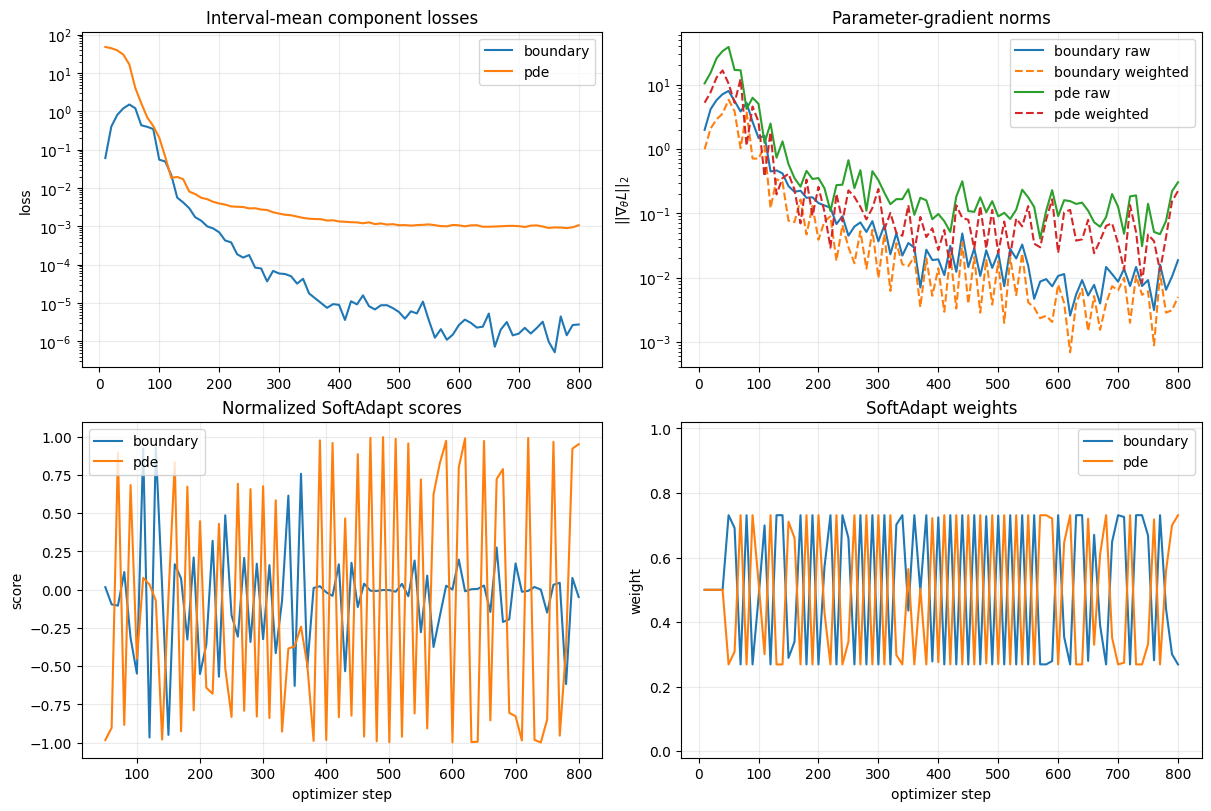

In [ ]:
steps = np.asarray([row["step"] for row in records])
fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)

for name in ("boundary", "pde"):
    axes[0, 0].semilogy(steps, [row[f"{name}_loss"] for row in records], label=name)
    axes[0, 1].semilogy(steps, [row[f"{name}_grad_norm"] for row in records], label=f"{name} raw")
    axes[0, 1].semilogy(steps, [row[f"{name}_weighted_grad_norm"] for row in records], "--", label=f"{name} weighted")
    axes[1, 0].plot(steps, [row[f"{name}_score"] for row in records], label=name)
    axes[1, 1].plot(steps, [row[f"{name}_weight"] for row in records], label=name)

axes[0, 0].set(title="Interval-mean component losses", ylabel="loss")
axes[0, 1].set(title="Parameter-gradient norms", ylabel=r"$||\nabla_\theta L||_2$")
axes[1, 0].set(title="Normalized SoftAdapt scores", ylabel="score", xlabel="optimizer step")
axes[1, 1].set(title="SoftAdapt weights", ylabel="weight", xlabel="optimizer step", ylim=(-0.02, 1.02))
for ax in axes.flat:
    ax.grid(alpha=0.25)
    ax.legend()

history_plot = output_dir / "diagnostics.png"
fig.savefig(history_plot, dpi=160)
plt.show()

## Learned solution

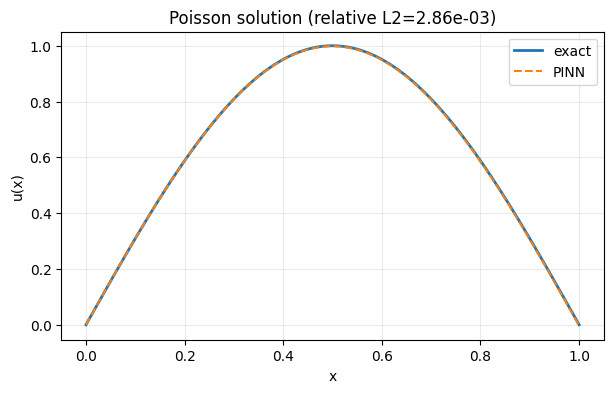

saved plots under results\softadapt_simple_pde/


In [ ]:
x_plot = torch.linspace(0.0, 1.0, 501, device=device).unsqueeze(1)
with torch.no_grad():
    prediction = model(x_plot).cpu().squeeze().numpy()
x_numpy = x_plot.cpu().squeeze().numpy()
exact = np.sin(np.pi * x_numpy)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(x_numpy, exact, label="exact", linewidth=2)
ax.plot(x_numpy, prediction, "--", label="PINN")
ax.set(xlabel="x", ylabel="u(x)", title=f"Poisson solution (relative L2={records[-1]['relative_l2']:.2e})")
ax.grid(alpha=0.25)
ax.legend()
solution_plot = output_dir / "solution.png"
fig.savefig(solution_plot, dpi=160, bbox_inches="tight")
plt.show()
print(f"saved plots under {output_dir.relative_to(ROOT)}/")